You are a data analyst working for a tech company closely monitoring the AI tools market. You want to understand the evolving popularity of three major AI tools, ChatGPT, Gemini, and Microsoft Copilot, and identify which tool is gaining the most traction and how they compare over time.


<img src="ai_tools.jpg" align="center"/>

You'll work with real-world time series data that captures the global interest in these tools over several weeks. Your goal is to analyze this data, uncover patterns, and provide actionable insights to help your company make informed decisions. This might include determining where to focus marketing efforts, predicting future trends, or identifying potential areas for improvement.

Are you ready to help your company stay ahead of the curve in the competitive AI tools market? Let's get started!

### The Data

The Google Trends data is available as a CSV file `ai_tools_comparison.csv`.
The data contains the number of worldwide searches for chatGpt, Gemini, and Microsoft Copilot over the past 12 months as of September 2024. 
<!--- Link to query: https://trends.google.com/trends/explore?q=chatgpt,gemini,%2Fg%2F11tsqm45vd&hl=en-US -->

In [111]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the data
trends.head()

,week,chatgpt,gemini,microsoft_copilot
0,2023-08-27,56,3,1
1,2023-09-03,56,3,1
2,2023-09-10,63,3,1
3,2023-09-17,64,3,1
4,2023-09-24,66,3,1


In [112]:
#Part 1
#week as index
trends = trends.set_index('week')

#week over week percentage change
weekly_changes = trends[['chatgpt', 'gemini', 'microsoft_copilot']].pct_change()

#standard deviation
change_std = weekly_changes.std()
change_std

chatgpt              0.090510
gemini               0.363603
microsoft_copilot    0.245632
dtype: float64

In [113]:
#most consistent tool
most_consistent_tool = change_std.idxmin()
most_consistent_tool

'chatgpt'

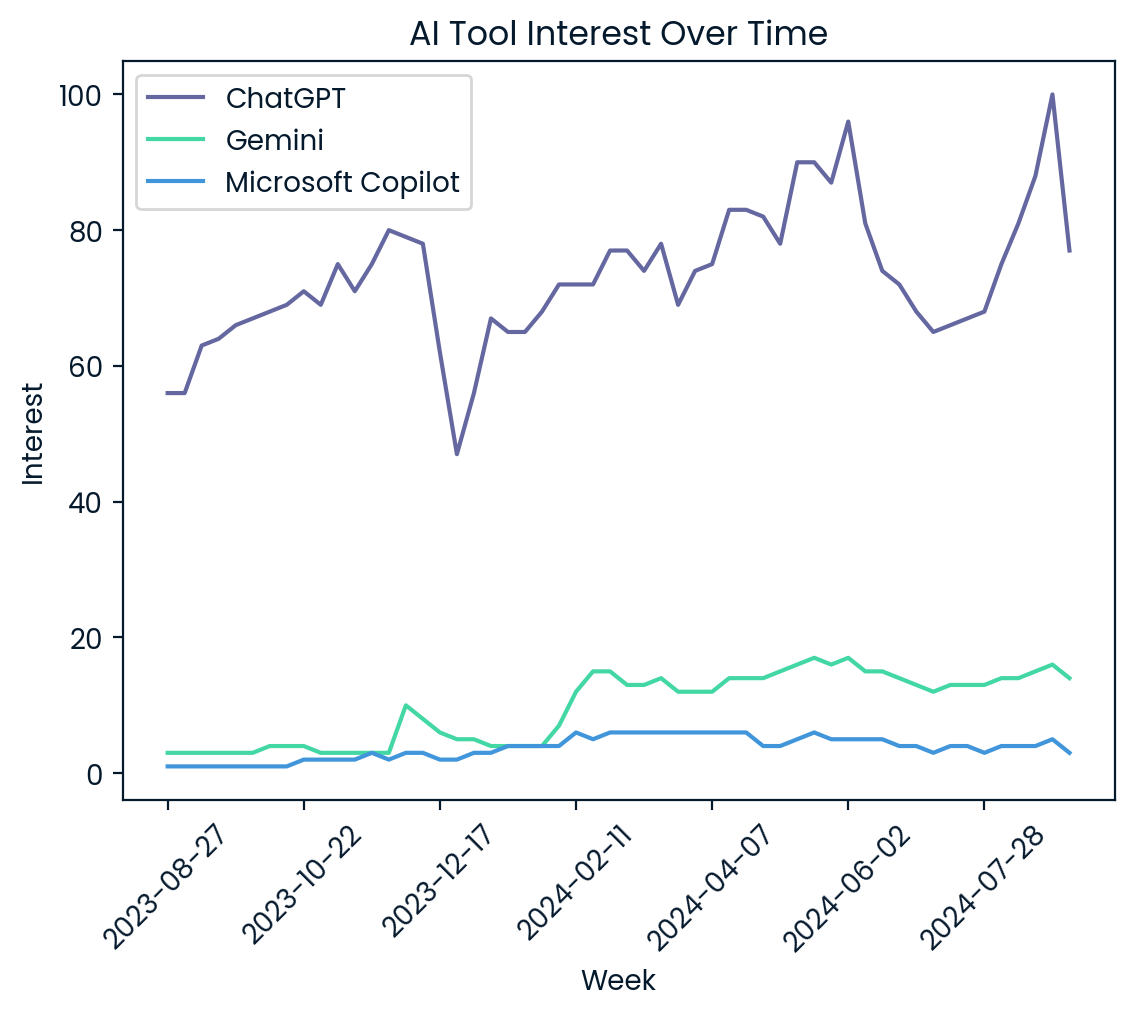

In [114]:
#Part 2
#interest levels over time
plt.plot(trends.index, trends['chatgpt'], label='ChatGPT')
plt.plot(trends.index, trends['gemini'], label='Gemini')
plt.plot(trends.index, trends['microsoft_copilot'], label='Microsoft Copilot')

plt.xlabel('Week')
plt.ylabel('Interest')
plt.title('AI Tool Interest Over Time')
plt.legend()

plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(8))
plt.show()

In [115]:
gpt_dip = 'December 2023'
gpt_dip

'December 2023'

In [116]:
#Part 3
#month column
trends['month'] = pd.to_datetime(trends.index).month_name()

#monthly averages
monthly_avg = trends.groupby('month')[['chatgpt', 'gemini', 'microsoft_copilot']].mean()

#average across all tools
monthly_avg['overall_avg'] = monthly_avg.mean(axis=1)

#best month
best_month = monthly_avg['overall_avg'].idxmax()
best_month

'May'